# What is GFTM getting wrong on R4, and where else? (Fusion_PhD-38e9.28)

Advisory agent analysis. Every number comes from pyro `pyroscan.nc` / `cube.nc` objects on Pitagora; nothing is read
from a CSV. Background (Fusion_PhD `results/beta_stabilisation_f05/README.md`, 38e9.9): above GS2 β ≈ 0.07 GFTM finds a
compact, even-parity, low-ω KBM on R4 that GS2 does not have; it is B∥-driven, rises with WIDTH and is not converged
in NXGRID.

1. **Numerical settings** on R4 (3 ky × 19 β): max basis (NBASIS 59 / NXGRID 65), FILTER, NMODES, IBRANCH,
   USE_MHD_RULE, velocity resolution (NU/NE). Leaves `GFTM/Runs/scan_beta_f05_diag/R4/*` (GyroRun).
2. **Extents** of every GFTM mode (FILTER 0, NMODES 8) against GS2's mode.
3. **Mode selection and frequency**: the whole unstable GFTM spectrum against GS2, and whether a selection rule finds
   the GS2-like mode.
4. **Other bad cases**: the KBM hypercubes, the β scans and the S1_3 q/ŝ scans, and what the badly-wrong cases share.

GS2 is initial-value: one mode per run, so there is no GS2 subdominant mode to compare against.

In [1]:
from pathlib import Path
import os
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter
from scipy.integrate import trapezoid
from dotenv import load_dotenv
import pyrokinetics
from pyrokinetics import PyroScan
from pyrokinetics.pyroscan import PyroScanGKOutput
from pyrokinetics.diagnostics import Diagnostics
from pyrokinetics.diagnostics.extent import Extent
from general_analysis import mode_classification as mc

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir()
)
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
print("pyrokinetics", pyrokinetics.__version__)

analysis_name = "gftm_r4_diagnosis"
data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
run_template = "Runs"
plot_dir = ROOT / "Plots" / analysis_name
plot_dir.mkdir(parents=True, exist_ok=True)

case = "R4"
ky_targets = [0.1, 0.2, 0.3]                  # snapped to GS2's grid
beta_high, beta_low = 0.07, 0.05              # GS2 beta numbers: high-beta cells >= 0.07, low-beta control <= 0.05
tol_unconverged = 0.1                         # GS2 growth_rate_tolerance at or above this: unconverged (38e9.9)
fraction = 0.95                               # pyro Extent fraction
gs2_leaf = ("GS2", "scan_beta", "parameter_scan_GS2")
# GFTM leaves on R4: label -> (project, leaf, WIDTH). "base" = FILTER 0.5, NMODES 2, NBASIS 12, NXGRID 32, NU 7, NE 3.
leaves = {
    "base w0.3": ("scan_beta_f05_conv", "width_0p3", 0.3),
    "base w0.8": ("scan_beta_f05", "w0p8", 0.8),
    "base w1.74": ("scan_beta", "parameter_scan_gftm_default", 1.74),   # beta labelled with GS2's numbers (f = 1)
    "nobpar w0.8": ("scan_beta_f05_conv", "nobpar_w0p8", 0.8),
    **{f"maxb w{w:g}": ("scan_beta_f05_diag", f"maxb_w{w:g}".replace(".", "p"), w) for w in (0.3, 0.8, 1.74)},
    **{f"spec w{w:g}": ("scan_beta_f05_diag", f"spec_w{w:g}".replace(".", "p"), w) for w in (0.3, 0.8, 1.74)},
    "spec maxb w0.8": ("scan_beta_f05_diag", "spec_maxb_w0p8", 0.8),
    "ibranch0 w0.8": ("scan_beta_f05_diag", "ibr0_w0p8", 0.8),
    "filter0.7 w0.8": ("scan_beta_f05_diag", "filt0p7_w0p8", 0.8),
    "filter0.9 w0.8": ("scan_beta_f05_diag", "filt0p9_w0p8", 0.8),
    "mhd w0.8": ("scan_beta_f05_diag", "mhd_w0p8", 0.8),
    "mhd nobpar w0.8": ("scan_beta_f05_diag", "mhd_nobpar_w0p8", 0.8),
    **{f"vel w{w:g}": ("scan_beta_f05_diag", f"vel_w{w:g}".replace(".", "p"), w) for w in (0.3, 0.8)},
}
fs_title, fs_label, fs_tick, fs_legend = 16, 16, 14, 12
field_label = {"phi": r"$\phi$", "apar": r"$A_\parallel$", "bpar": r"$B_\parallel$"}

pyrokinetics 0.9.2.dev149+gf119e687


## Load R4: GS2 and every GFTM leaf
Each leaf is a PyroScan with its `pyroscan.nc`; pyro `Extent` (95%) is added per field and mode. GFTM's ky grid is
selected onto GS2's three ky (asserted), and β is matched by index (GFTM stores pyro β = GS2 β × f, asserted constant).

In [2]:
def v(da):
    return np.asarray(getattr(da.data, "magnitude", da.data))


def load_leaf(code, project, leaf):
    d = data_root / code / run_template / project / case / leaf
    s = PyroScan(pyroscan_json=d / "pyroscan.json", load_base_pyro=True)
    s.load_gk_output(netcdf_file=d / "pyroscan.nc")
    Extent(s.gk_output, fraction=fraction)
    out = s.gk_output.data
    for dim in ("bpar", "kx"):   # nobpar leaves scan numerics.bpar = [False]; GFTM writes a length-1 kx
        out = out.squeeze(dim, drop=True) if dim in out.dims else out
    return out


gs2_all = load_leaf(*gs2_leaf)
iky = [int(np.abs(v(gs2_all.ky) - k).argmin()) for k in ky_targets]
G = gs2_all.isel(ky=iky).transpose("ky", "beta", ...)
beta = v(G.beta)
ky = v(G.ky)
tol = v(G.growth_rate_tolerance)
unconv = tol >= tol_unconverged
hi, lo = beta >= beta_high, beta <= beta_low
g_gs2, w_gs2 = v(G.growth_rate), v(G.mode_frequency)

R = {}
for lab, (project, leaf, _) in leaves.items():
    d = load_leaf("GFTM", project, leaf)
    d = d.sel(ky=ky, method="nearest").transpose("ky", "beta", "mode", ...)
    assert np.allclose(v(d.ky), ky, atol=1e-3) and d.beta.size == beta.size, lab
    f = v(d.beta) / beta
    assert np.allclose(f, f[0], rtol=1e-3), (lab, "beta is not GS2 beta x constant")
    R[lab] = d
print("ky", ky.round(3), "| GS2 beta", beta.round(2))
print("modes per leaf:", {lab: int(d.mode.size) for lab, d in R.items()})
print("GS2 unconverged (tol >= 0.1) at beta >= 0.07:", int(unconv[:, hi].sum()), "of", int(hi.sum() * len(ky)))

ky [0.112 0.2   0.3  ] | GS2 beta [0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13 0.14
 0.15 0.16 0.17 0.18 0.19]
modes per leaf: {'base w0.3': 2, 'base w0.8': 2, 'base w1.74': 2, 'nobpar w0.8': 2, 'maxb w0.3': 2, 'maxb w0.8': 2, 'maxb w1.74': 2, 'spec w0.3': 8, 'spec w0.8': 8, 'spec w1.74': 8, 'spec maxb w0.8': 8, 'ibranch0 w0.8': 2, 'filter0.7 w0.8': 2, 'filter0.9 w0.8': 2, 'mhd w0.8': 2, 'mhd nobpar w0.8': 2, 'vel w0.3': 2, 'vel w0.8': 2}
GS2 unconverged (tol >= 0.1) at beta >= 0.07: 31 of 39


## (1) Numerical settings
Dominant mode = argmax γ over `mode`. GFTM clamps stable cells (no unstable mode) to γ = 0, so they score γ = 0.
Metric: `LogMed |γ_GFTM − γ_GS2|` (log10 of the median absolute error) over the high-β cells (β ≥ 0.07, n = 39)
and over the low-β control (β ≤ 0.05, n = 15), where GS2 is converged and the codes agreed in 38e9.9.

In [3]:
def dominant(d, name):
    m = np.nan_to_num(v(d.growth_rate), nan=-np.inf).argmax(-1)
    return d[name].isel(mode=xr.DataArray(m, dims=("ky", "beta")))


def gamma_dom(d):
    g = v(dominant(d, "growth_rate"))
    return np.where(np.isfinite(g) & (g > 0), g, 0.0)


def logmed(g, mask):
    return float(np.log10(np.median(np.abs(g - g_gs2)[mask])))


g = {lab: gamma_dom(d) for lab, d in R.items()}
w = {lab: v(dominant(d, "mode_frequency")) for lab, d in R.items()}
summary = pd.DataFrame({lab: {"WIDTH": leaves[lab][2], "LogMed hi": logmed(g[lab], hi[None, :] & np.ones((3, 1), bool)),
                              "LogMed lo": logmed(g[lab], lo[None, :] & np.ones((3, 1), bool)),
                              **{f"max g hi ky{k:.2f}": g[lab][i, hi].max() for i, k in enumerate(ky)}}
                        for lab in R}).T
print("GS2 max gamma at beta >= 0.07 per ky:", g_gs2[:, hi].max(1).round(3))
print(summary.round(3).to_string())

GS2 max gamma at beta >= 0.07 per ky: [0.018 0.012 0.005]
                 WIDTH  LogMed hi  LogMed lo  max g hi ky0.11  max g hi ky0.20  max g hi ky0.30
base w0.3         0.30     -1.329     -1.929            0.058            0.125            0.101
base w0.8         0.80     -0.440     -1.705            0.948            0.778            0.325
base w1.74        1.74     -0.170     -0.888            0.975            0.737            0.347
nobpar w0.8       0.80     -1.696     -0.821            0.015            0.021            0.252
maxb w0.3         0.30     -1.682     -2.047            0.019            0.039            0.047
maxb w0.8         0.80     -1.022     -2.046            0.134            0.357            0.285
maxb w1.74        1.74     -0.274     -1.287            1.019            0.880            0.514
spec w0.3         0.30     -1.329     -1.929            0.058            0.125            0.101
spec w0.8         0.80     -0.440     -1.705            0.948            0.778

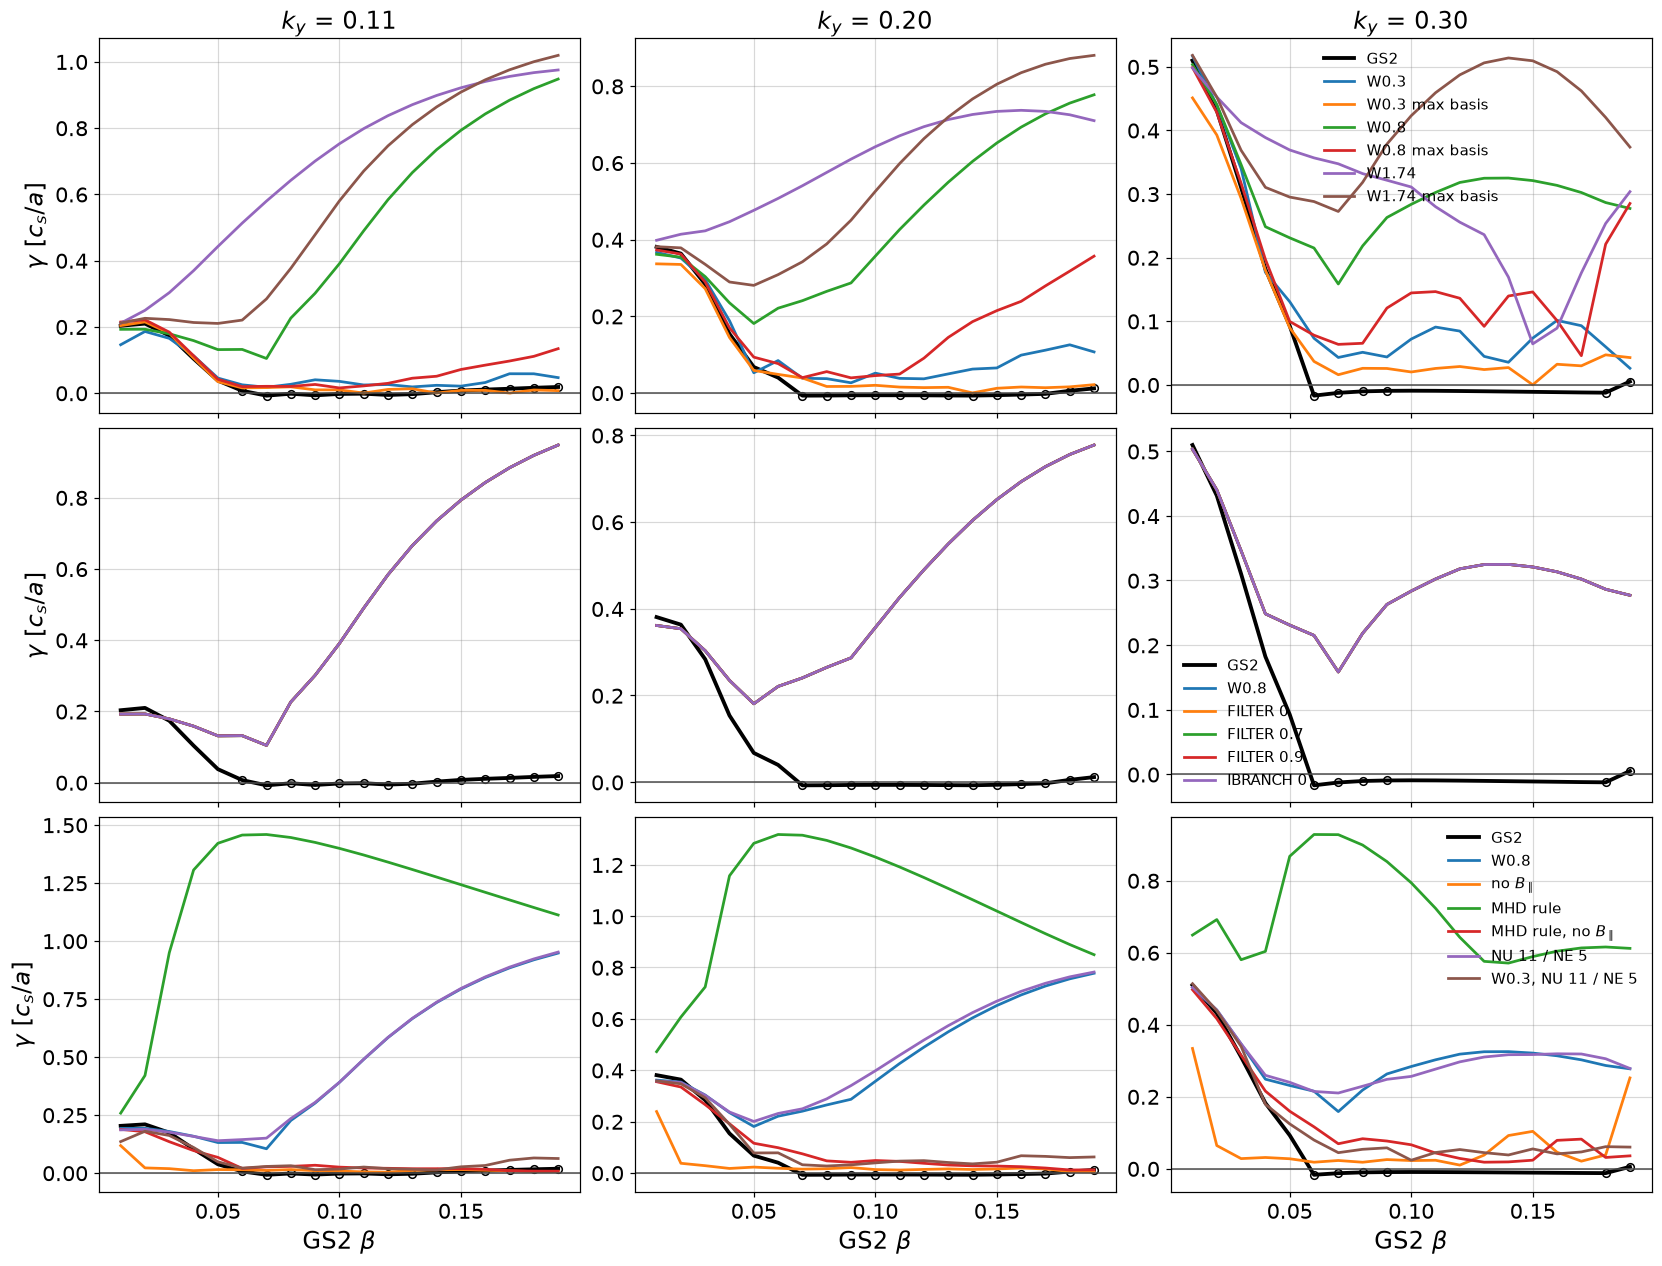

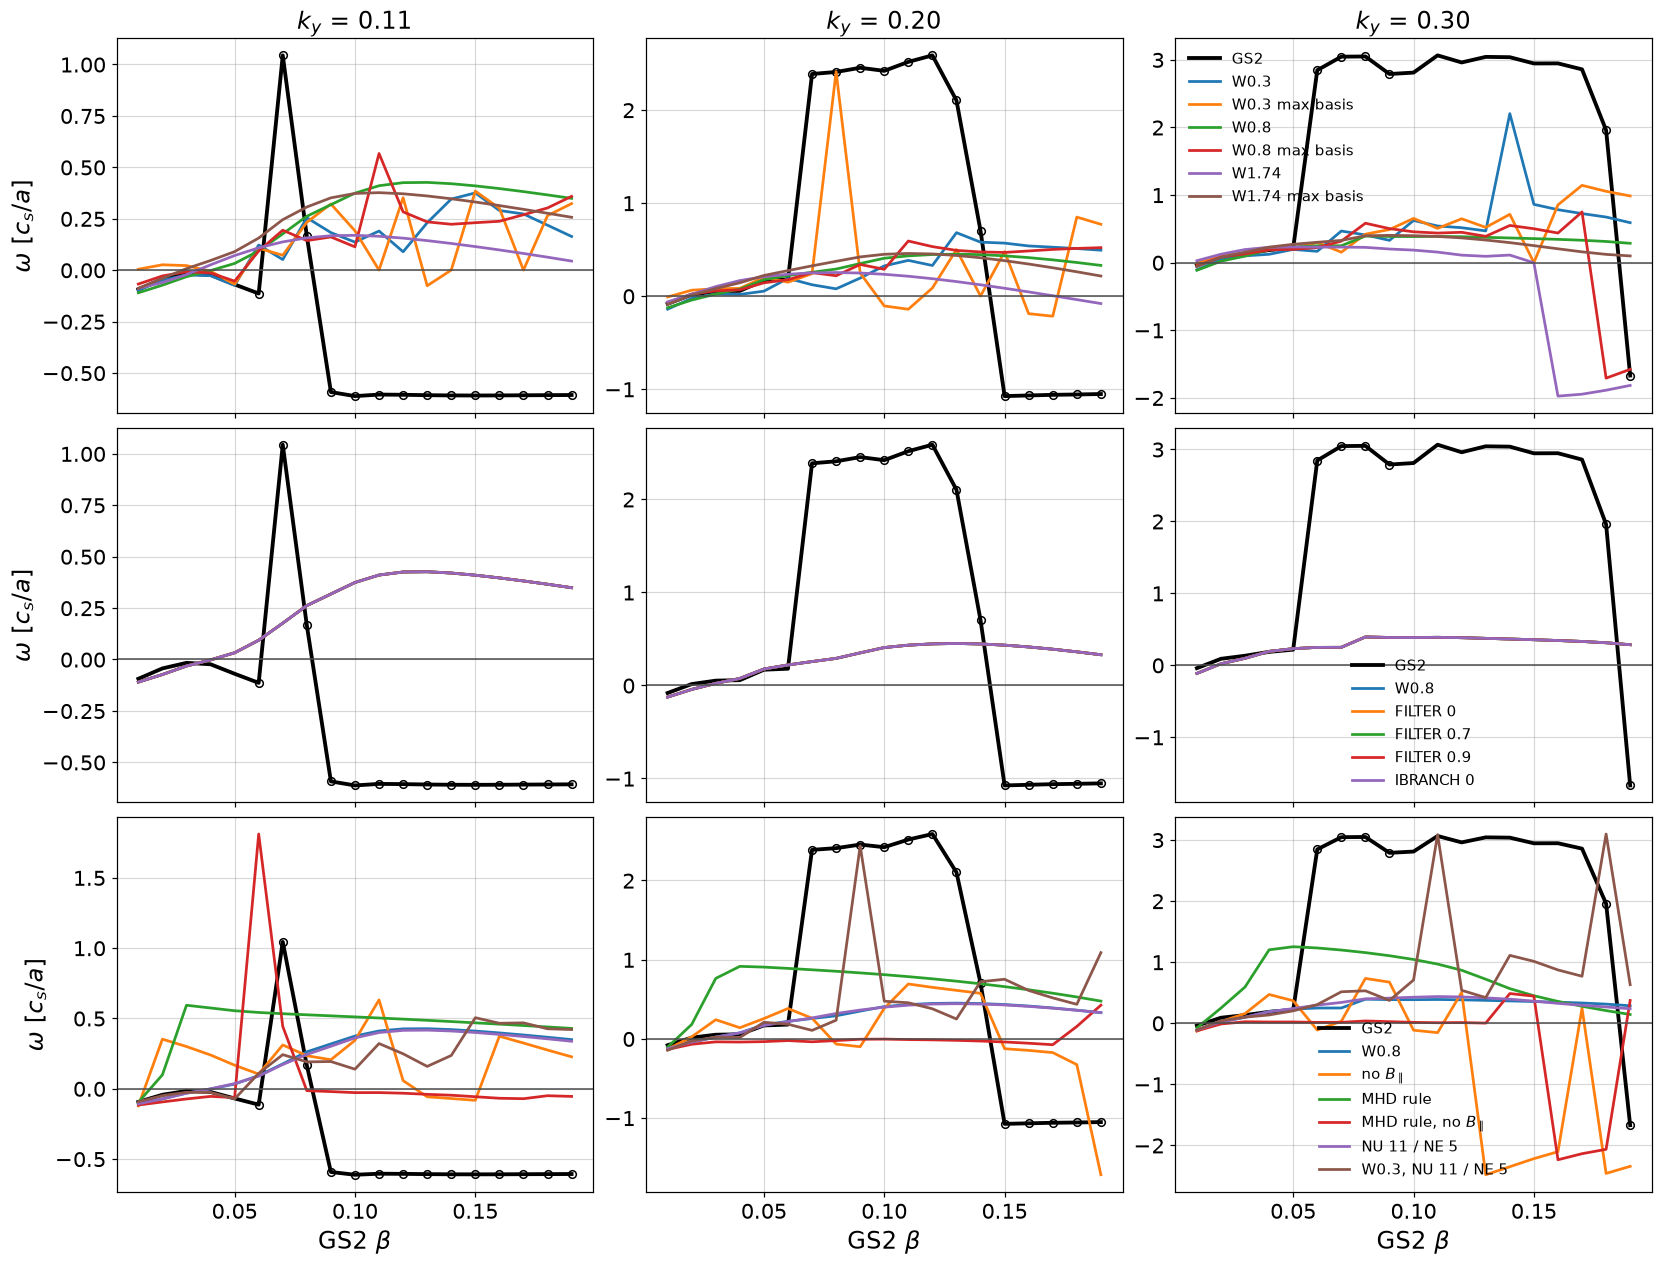

In [5]:
groups = {
    "basis": ["base w0.3", "maxb w0.3", "base w0.8", "maxb w0.8", "base w1.74", "maxb w1.74"],
    "selection": ["base w0.8", "spec w0.8", "filter0.7 w0.8", "filter0.9 w0.8", "ibranch0 w0.8"],
    "physics": ["base w0.8", "nobpar w0.8", "mhd w0.8", "mhd nobpar w0.8", "vel w0.8", "vel w0.3"],
}
short = {"base w0.3": "W0.3", "maxb w0.3": "W0.3 max basis", "base w0.8": "W0.8", "maxb w0.8": "W0.8 max basis",
         "base w1.74": "W1.74", "maxb w1.74": "W1.74 max basis", "spec w0.8": "FILTER 0", "filter0.7 w0.8": "FILTER 0.7",
         "filter0.9 w0.8": "FILTER 0.9", "ibranch0 w0.8": "IBRANCH 0", "nobpar w0.8": r"no $B_\parallel$",
         "mhd w0.8": "MHD rule", "mhd nobpar w0.8": r"MHD rule, no $B_\parallel$", "vel w0.8": "NU 11 / NE 5",
         "vel w0.3": "W0.3, NU 11 / NE 5"}
figs_set = {}
for var, ylab, data, ref in (("gamma", r"$\gamma$ [$c_s/a$]", g, g_gs2), ("omega", r"$\omega$ [$c_s/a$]", w, w_gs2)):
    fig, axes = plt.subplots(len(groups), len(ky), figsize=(5 * len(ky), 3.8 * len(groups)), sharex=True)
    for row, (grp, labs) in enumerate(groups.items()):
        for col in range(len(ky)):
            ax = axes[row, col]
            ax.plot(beta, ref[col], color="k", lw=2.5, label="GS2", marker="none")
            ax.plot(beta[unconv[col]], ref[col, unconv[col]], color="k", ls="", marker="o", ms=5, mfc="none")
            for n, lab in enumerate(labs):
                ax.plot(beta, data[lab][col], color=f"C{n}", label=short[lab], marker="none")
            ax.axhline(0, color="0.3", lw=1, marker="")
            ax.tick_params(labelsize=fs_tick)
            if row == 0:
                ax.set_title(rf"$k_y$ = {ky[col]:.2f}", fontsize=fs_title)
        axes[row, 0].set_ylabel(ylab, fontsize=fs_label)
        axes[row, -1].legend(fontsize=10)
    for ax in axes[-1]:
        ax.set_xlabel(r"GS2 $\beta$", fontsize=fs_label)
    fig.savefig(plot_dir / f"gs2_gftm_{var}_vs_beta_r4.png", dpi=150, bbox_inches="tight")
    figs_set[var] = fig
plt.show()

### Settings audit
What each leaf ran is in its `pyroscan.json` (requested) and per run in `input.gftm.gen` / `out.gftm.localdump`
(used); the count audit is Fusion_PhD `tools/pitagora_scans/gyrorun_leaf_audit.py` (its result is in the Fusion_PhD
README). Here: IBRANCH 0 returns the most unstable mode of each frequency sign in fixed slots.

In [6]:
d = R["ibranch0 w0.8"]
wi = v(d.mode_frequency)
for m in range(d.mode.size):
    ok = np.isfinite(wi[..., m]) & (v(d.growth_rate)[..., m] > 0)
    print(f"IBRANCH 0, mode slot {m}: unstable in {ok.sum()} of {ok.size} cells, omega sign +{(wi[..., m][ok] > 0).sum()} / "
          f"-{(wi[..., m][ok] < 0).sum()}")

IBRANCH 0, mode slot 0: unstable in 57 of 57 cells, omega sign +0 / -57
IBRANCH 0, mode slot 1: unstable in 57 of 57 cells, omega sign +57 / -0
